# Regression: the Workhorse of Applied Statistics

**What you'll learn**

- How to run the same OLS machinery in two different mindsets — inference
  (coefficients, SEs, identification) vs prediction (held-out error) — and why
  mixing them up is the most common senior-level regression mistake.
- Fluent coefficient reading across functional forms: levels, log-x, log-y,
  log-log (elasticities), dummies, and interactions — practiced on a simulated
  pricing dataset where every true coefficient is known.
- Omitted variable bias as arithmetic you can verify: the short-vs-long
  regression identity, sign intuition, and a confounded pricing example where
  the estimated elasticity flips sign.
- Which diagnostics actually matter: heteroskedasticity (fix: robust SEs —
  shown to matter via a coverage simulation), functional form (residual plots),
  and why residual normality is mostly a red herring at realistic n.
- What multicollinearity does (inflates SEs of the collinear coefficients) and
  does not do (hurt prediction or the other coefficients), with VIF arithmetic
  verified by simulation.
- Ridge and lasso: coefficient paths, why standardization is non-negotiable,
  and why lasso "selected" variables are a predictive convenience, not causal
  or inferential findings.
- Logistic regression outputs stakeholders can use: odds ratios vs average
  marginal effects, computed both by `statsmodels` and by hand.

**Why it matters in interviews**

- "Interpret this coefficient" is the single most common statistics screener
  for DS roles — and it is usually asked with a log, a dummy, or an
  interaction precisely to catch shallow answers.
- "Can you conclude X causes Y from this regression?" separates candidates who
  know regression is a conditioning machine from those who read coefficients
  causally by default.
- Experimentation and econometrics-flavored roles probe robust SEs, OVB
  direction ("which way is the bias?"), and multicollinearity folklore.
- ML-flavored roles probe ridge vs lasso trade-offs and whether you know what
  regularization costs you (unbiasedness, valid inference), not just what it
  buys you.

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy.linalg import toeplitz
from sklearn.linear_model import Lasso, LassoCV, Ridge, RidgeCV, lasso_path
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 120)

## 1. Two mindsets, one tool

Regression serves two different jobs, and almost every regression mistake in
industry comes from doing one job while implicitly claiming the other:

| | **Inference** | **Prediction** |
|---|---|---|
| Target | a coefficient $\beta_j$ (an effect, an elasticity) | $\hat{y}$ for new units |
| Quality metric | bias of $\hat\beta_j$, SE validity, CI coverage | held-out RMSE / log-loss |
| What can ruin it | confounding, measurement error, wrong SEs | leakage, overfitting, drift |
| Extra variables | only if they aid *identification* (confounders yes, colliders/mediators no) | anything that predicts, provenance irrelevant |
| Regularization | biases coefficients — use with care | usually helps |
| Canonical failure | "price elasticity is +0.2, raise prices!" | great R², useless out of sample |

The same fitted object can be excellent for one job and terrible for the
other. A confounded regression can fit respectably (§3's short regression has
R² ≈ 0.3) while its key coefficient has the *wrong sign*; a well-identified
experiment regression can have R² ≈ 0.0003 and still be worth millions (§8).
Throughout this notebook we will keep asking: *which job is this regression
doing?*

For the prediction-first toolkit (validation design, boosting) see
`../04_ml_tabular/`; for what it takes to earn a causal reading, see
`../03_causal_inference/01_potential_outcomes_dags.ipynb`. This notebook
builds the shared foundation.

## 2. Coefficient interpretation practice: a pricing dataset with known truth

We simulate store-week sales for a packaged-goods product with a
**constant-elasticity (log-log) demand curve** — the standard model in pricing
work — plus promo/holiday dummies and an ad-spend term. Because we wrote the
data-generating process, every regression below can be graded against truth:

$$\log(\text{units}) = 4.0 \;-\; 1.8\,\widetilde{\log p} \;+\; 0.25\,\text{promo}
\;-\; 0.7\,\text{promo}\cdot\widetilde{\log p} \;+\; 0.18\,\text{holiday}
\;+\; 0.10\,\log(\text{ad}) \;+\; \varepsilon$$

where $\widetilde{\log p} = \log(\text{price}) - \log(4)$ is log-price
**centered at the $4 reference price** (this centering will matter a lot for
the interaction), and $\varepsilon \sim N(0, 0.25^2)$. True baseline price
elasticity: **−1.8**; on promo weeks the interaction makes shoppers more
price-sensitive: elasticity **−2.5**. Price, promo, ads, and holidays are
mutually independent here — a luxury real data never grants (that's §3).

In [2]:
n = 6_000
price = np.exp(rng.normal(np.log(4.0), 0.30, n))       # lognormal around $4
promo = rng.binomial(1, 0.25, n)
holiday = rng.binomial(1, 0.15, n)
ad_spend = np.exp(rng.normal(np.log(500), 0.6, n))     # weekly local ad $, skewed

lp_c = np.log(price) - np.log(4.0)                     # log-price centered at $4

TRUE = {"Intercept": 4.0, "lp_c": -1.8, "promo": 0.25,
        "lp_c:promo": -0.7, "holiday": 0.18, "np.log(ad_spend)": 0.10}

log_units = (TRUE["Intercept"] + TRUE["lp_c"] * lp_c + TRUE["promo"] * promo
             + TRUE["lp_c:promo"] * promo * lp_c + TRUE["holiday"] * holiday
             + TRUE["np.log(ad_spend)"] * np.log(ad_spend)
             + rng.normal(0, 0.25, n))

sales = pd.DataFrame({"price": price, "promo": promo, "holiday": holiday,
                      "ad_spend": ad_spend, "lp_c": lp_c,
                      "units": np.exp(log_units), "log_units": log_units})
print(sales[["price", "ad_spend", "units"]].describe().round(1))

        price  ad_spend   units
count  6000.0    6000.0  6000.0
mean      4.2     607.7   140.9
std       1.3     389.7   113.5
min       1.1      54.3    11.2
25%       3.3     337.9    72.7
50%       4.0     509.0   110.4
75%       4.8     762.8   172.8
max      11.3    4223.5  1530.7


### 2.1 Levels: `units ~ price`

The slope of a levels regression is "units per dollar" — a *local linear
approximation* to a curve that is not a line. It is not wrong, but it is only
an average slope over the price range you observed, and it will change if the
price distribution changes. Compare the fitted line to the true demand curve:

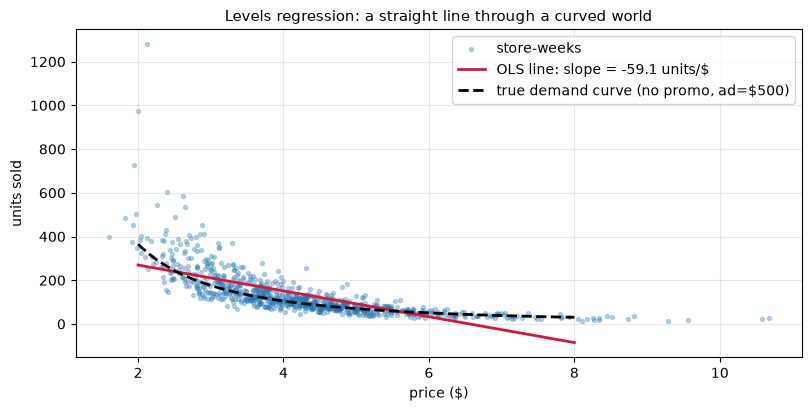

OLS levels slope:                -59.1 units per $1 of price
true derivative at price=$4:     -47.2 units per $1 (no promo)
Reading: 'each extra dollar of price costs ~59 units/week on average over the observed price range'.


In [3]:
res_lvl = smf.ols("units ~ price", data=sales).fit()
b_lvl = res_lvl.params["price"]

# true expected demand curve at promo=0, holiday=0, ad=$500 (lognormal mean shift)
p_grid = np.linspace(2, 8, 100)
true_curve = np.exp(TRUE["Intercept"] + TRUE["np.log(ad_spend)"] * np.log(500)
                    + 0.25**2 / 2) * (p_grid / 4.0) ** TRUE["lp_c"]

fig, ax = plt.subplots(figsize=(8, 4))
sub = sales.sample(800, random_state=42)
ax.scatter(sub["price"], sub["units"], s=8, alpha=0.3, label="store-weeks")
ax.plot(p_grid, res_lvl.predict(pd.DataFrame({"price": p_grid})), color="crimson",
        lw=2, label=f"OLS line: slope = {b_lvl:.1f} units/$")
ax.plot(p_grid, true_curve, color="black", ls="--", lw=2,
        label="true demand curve (no promo, ad=$500)")
ax.set(title="Levels regression: a straight line through a curved world",
       xlabel="price ($)", ylabel="units sold")
ax.legend()
plt.show()

d_at_4 = TRUE["lp_c"] * true_curve[np.argmin(np.abs(p_grid - 4.0))] / 4.0
print(f"OLS levels slope:              {b_lvl:7.1f} units per $1 of price")
print(f"true derivative at price=$4:   {d_at_4:7.1f} units per $1 (no promo)")
print("Reading: 'each extra dollar of price costs ~"
      f"{abs(b_lvl):.0f} units/week on average over the observed price range'.")

### 2.2 Log-y, log-x, log-log: the interpretation cheat sheet

| Model | Coefficient $b$ means | Exact version |
|---|---|---|
| $y \sim x$ | 1-unit ↑ in $x$ → $b$ **units** of $y$ | exact (by construction) |
| $\log y \sim x$ | 1-unit ↑ in $x$ → $\approx 100b\%$ change in $y$ | $(e^{b}-1)\times100\%$ |
| $y \sim \log x$ | 1% ↑ in $x$ → $\approx b/100$ **units** of $y$ | $b\log(1.01)$ |
| $\log y \sim \log x$ | 1% ↑ in $x$ → $\approx b\%$ change in $y$: an **elasticity** | $(1.01^{b}-1)\times100\%$ |

The approximations are good for small $|b|$ and small changes; §2.3 shows
where the sloppy version embarrasses you (large dummy coefficients). Below,
each form fitted to the same data:

In [4]:
res_logy = smf.ols("log_units ~ price", data=sales).fit()
res_logx = smf.ols("units ~ np.log(price)", data=sales).fit()
res_ll = smf.ols("log_units ~ np.log(price)", data=sales).fit()

b = res_logy.params["price"]
print(f"log-y   : b = {b:+.3f}  -> a 10-cent price increase changes units by "
      f"~{100 * b * 0.10:+.1f}%")
b = res_logx.params["np.log(price)"]
print(f"log-x   : b = {b:+.1f}   -> a 1% price increase changes units by "
      f"~{b / 100:+.2f} units")
b = res_ll.params["np.log(price)"]
print(f"log-log : b = {b:+.3f}  -> a 1% price increase changes units by ~{b:+.2f}% "
      "(elasticity)")
print(f"\nTrue *average* elasticity (25% promo weeks at -2.5, else -1.8): "
      f"{0.75 * -1.8 + 0.25 * -2.5:+.3f}")
print("The bivariate log-log slope lands on the promo-share-weighted average "
      "elasticity\nbecause promo is independent of price here (no confounding).")

log-y   : b = -0.451  -> a 10-cent price increase changes units by ~-4.5%
log-x   : b = -283.1   -> a 1% price increase changes units by ~-2.83 units
log-log : b = -1.966  -> a 1% price increase changes units by ~-1.97% (elasticity)

True *average* elasticity (25% promo weeks at -2.5, else -1.8): -1.975
The bivariate log-log slope lands on the promo-share-weighted average elasticity
because promo is independent of price here (no confounding).


### 2.3 The full model: dummies, interactions, and grading against truth

Now the correctly specified model. Note the two dummy-reading rules every
senior candidate should fire off automatically:

1. **Dummies in a log-y model are multiplicative**: the exact effect is
   $e^{b}-1$, not $b$. Fine for small $b$ (0.05 → 5.1%), badly wrong for
   large $b$ (0.7 → **101%**, not 70%).
2. **With an interaction, "main effects" are effects at zero of the other
   variable.** We centered log-price at $4, so `promo` reads "promo lift *at
   the $4 reference price*" — exactly the quantity marketing would ask for.

In [5]:
res_full = smf.ols("log_units ~ lp_c * promo + holiday + np.log(ad_spend)",
                   data=sales).fit()

order = ["Intercept", "lp_c", "promo", "lp_c:promo", "holiday", "np.log(ad_spend)"]
grade = pd.DataFrame({"estimate": res_full.params, "se": res_full.bse,
                      "true": pd.Series(TRUE)}).loc[order].round(3)
print(grade)

b_promo = res_full.params["promo"]
b_hol = res_full.params["holiday"]
print(f"\npromo lift at $4:  approx {100 * b_promo:.1f}%,  "
      f"exact {100 * (np.exp(b_promo) - 1):.1f}%   (true: "
      f"{100 * (np.exp(TRUE['promo']) - 1):.1f}%)")
print(f"holiday lift:      approx {100 * b_hol:.1f}%,  "
      f"exact {100 * (np.exp(b_hol) - 1):.1f}%")
print(f"large-b example:   b = 0.70 reads as 'approx 70%' but is exactly "
      f"{100 * (np.exp(0.70) - 1):.1f}%")

el_base = res_full.params["lp_c"]
el_promo = el_base + res_full.params["lp_c:promo"]
print(f"\nelasticity, regular weeks: {el_base:+.2f}   (true -1.80)")
print(f"elasticity, promo weeks:   {el_promo:+.2f}   (true -2.50)")

                  estimate     se  true
Intercept            4.001  0.034  4.00
lp_c                -1.794  0.013 -1.80
promo                0.249  0.008  0.25
lp_c:promo          -0.722  0.025 -0.70
holiday              0.186  0.009  0.18
np.log(ad_spend)     0.100  0.005  0.10

promo lift at $4:  approx 24.9%,  exact 28.2%   (true: 28.4%)
holiday lift:      approx 18.6%,  exact 20.4%
large-b example:   b = 0.70 reads as 'approx 70%' but is exactly 101.4%

elasticity, regular weeks: -1.79   (true -1.80)
elasticity, promo weeks:   -2.52   (true -2.50)


### 2.4 Why we centered: the same model without centering

Refit with raw `log(price)` instead of the centered version. The model is
mathematically identical (same fit, same predictions, same elasticities) —
but the `promo` coefficient now means "promo lift at log(price) = 0", i.e.
**at a price of $1**, far outside the data. Anyone reading it as "the promo
effect" gets a wild number:

In [6]:
res_unc = smf.ols("log_units ~ np.log(price) * promo + holiday + np.log(ad_spend)",
                  data=sales).fit()

print(f"centered model   promo coef: {res_full.params['promo']:+.3f}  "
      f"-> {100 * (np.exp(res_full.params['promo']) - 1):+.1f}% lift at $4  (sensible)")
print(f"uncentered model promo coef: {res_unc.params['promo']:+.3f}  "
      f"-> {100 * (np.exp(res_unc.params['promo']) - 1):+.1f}% 'lift' at $1  (!!)")
print(f"R-squared identical: {res_full.rsquared:.6f} vs {res_unc.rsquared:.6f}")
print("\nNothing is wrong with the uncentered fit - only with reading its main "
      "effect\nas 'the' promo effect. With interactions, always ask: 'at what "
      "value of the\nother variable?' Center (or report effects at named values) "
      "so the answer is useful.")

centered model   promo coef: +0.249  -> +28.2% lift at $4  (sensible)
uncentered model promo coef: +1.249  -> +248.7% 'lift' at $1  (!!)
R-squared identical: 0.855532 vs 0.855532

Nothing is wrong with the uncentered fit - only with reading its main effect
as 'the' promo effect. With interactions, always ask: 'at what value of the
other variable?' Center (or report effects at named values) so the answer is useful.


## 3. Omitted variable bias: the arithmetic of confounding

Real pricing data is confounded: managers **raise prices when demand is hot**
(seasonality, buzz, stockouts elsewhere). If the analyst can't observe the
demand state, price inherits its effect. The bias is not vague — it is exact
arithmetic. For a "long" regression $y = \beta_0 + \beta_1 x + \gamma q + e$
and a "short" one omitting $q$:

$$\hat\beta_1^{\text{short}} \;=\; \hat\beta_1^{\text{long}} \;+\; \hat\gamma \cdot \hat\delta,
\qquad \hat\delta = \text{slope of } q \text{ on } x .$$

This identity holds **exactly in-sample**, not just in expectation. Sign
intuition follows immediately — bias = (effect of omitted on $y$) × (relation
of omitted to included):

| $\gamma$: omitted → y | $\delta$: omitted ↔ included | bias in $\hat\beta_1^{\text{short}}$ |
|---|---|---|
| + | + | upward |
| + | − | downward |
| − | + | downward |
| − | − | upward |

Here demand heat raises sales ($\gamma > 0$) and raises price ($\delta > 0$),
so the naive elasticity is biased **upward** — badly enough to flip sign.

In [7]:
n_ovb = 4_000
q = rng.normal(0, 1, n_ovb)                       # demand heat (unobserved)
lp = 0.35 * q + rng.normal(0, 0.20, n_ovb)        # managers price into demand
lu = 4.6 - 1.5 * lp + 1.2 * q + rng.normal(0, 0.30, n_ovb)

short = sm.OLS(lu, sm.add_constant(lp)).fit()
Xlong = sm.add_constant(np.column_stack([lp, q]))
long = sm.OLS(lu, Xlong).fit()
aux = sm.OLS(q, sm.add_constant(lp)).fit()        # omitted on included

b_short, b_long = short.params[1], long.params[1]
gam, delta = long.params[2], aux.params[1]

print(f"true elasticity:                    -1.50")
print(f"long  regression (controls q):      {b_long:+.3f}")
print(f"short regression (omits q):         {b_short:+.3f}   <- sign flipped!")
print(f"\nOVB identity: short = long + gamma*delta")
print(f"  long + gamma*delta = {b_long:+.3f} + {gam:.3f} * {delta:.3f} "
      f"= {b_long + gam * delta:+.3f}")
print(f"  identity error: {abs(b_short - (b_long + gam * delta)):.2e}  (exact, "
      "up to float precision)")
print(f"\ntheory delta = cov(q, lp)/var(lp) = 0.35/(0.35^2 + 0.20^2) = "
      f"{0.35 / (0.35**2 + 0.20**2):.3f}; observed {delta:.3f}")
print(f"short-regression R^2 = {short.rsquared:.2f} - a perfectly respectable "
      "fit.\nGoodness of fit is silent about identification.")

true elasticity:                    -1.50
long  regression (controls q):      -1.507
short regression (omits q):         +1.120   <- sign flipped!

OVB identity: short = long + gamma*delta
  long + gamma*delta = -1.507 + 1.205 * 2.179 = +1.120
  identity error: 1.11e-15  (exact, up to float precision)

theory delta = cov(q, lp)/var(lp) = 0.35/(0.35^2 + 0.20^2) = 2.154; observed 2.179
short-regression R^2 = 0.31 - a perfectly respectable fit.
Goodness of fit is silent about identification.


The fix is a research design, not a bigger regression: randomize price,
find an instrument (cost shocks — see
`../03_causal_inference/04_iv_rdd.ipynb`), or measure and control the
confounder. Which controls help and which actively hurt (colliders,
post-treatment variables) is the subject of
`../03_causal_inference/01_potential_outcomes_dags.ipynb` — the rule is
emphatically *not* "add everything you have".

## 4. Diagnostics that matter — and ones that don't

The classical checklist (normality! homoskedasticity!) misallocates worry.
Ranked by what actually damages conclusions in practice:

1. **Identification / functional form** — biases coefficients (§3, §4.3).
2. **Wrong SEs**: heteroskedasticity, and above all **clustered/dependent
   data** — invalidates CIs and p-values (§4.1; clustering is covered in
   `../02_ab_testing/05_ratio_metrics_delta_method.ipynb`).
3. **Residual normality** — almost irrelevant for coefficient inference at
   realistic n (§4.2); it matters for *prediction intervals*.

### 4.1 Heteroskedasticity: coefficients fine, naive SEs too small

Error variance that grows with $x$ is the norm in business data (bigger
stores, bigger spenders → noisier outcomes). OLS coefficients stay unbiased;
the *naive SE formula* is what breaks. We measure the damage the honest way —
a coverage simulation: 2,000 datasets, does the nominal 95% CI contain the
true slope 95% of the time?

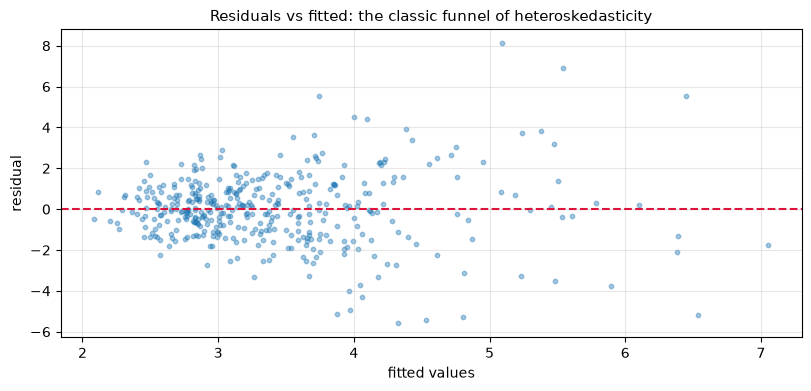

Breusch-Pagan test: LM = 73.4, p = 1.03e-17 (formal confirmation, but the plot already told us)


In [8]:
def draw_hetero(n_h):
    x = np.exp(rng.normal(1.0, 0.5, n_h))              # store size proxy, skewed
    y = 2.0 + 0.5 * x + rng.normal(0, 0.4 + 0.4 * x)   # noise grows with x
    return x, y

x_h, y_h = draw_hetero(400)
res_h = sm.OLS(y_h, sm.add_constant(x_h)).fit()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(res_h.fittedvalues, res_h.resid, s=10, alpha=0.4)
ax.axhline(0, color="crimson", ls="--")
ax.set(title="Residuals vs fitted: the classic funnel of heteroskedasticity",
       xlabel="fitted values", ylabel="residual")
plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan(res_h.resid, res_h.model.exog)
print(f"Breusch-Pagan test: LM = {bp_stat:.1f}, p = {bp_p:.2e} "
      "(formal confirmation, but the plot already told us)")

In [9]:
REPS, N_H, TRUE_SLOPE = 2_000, 200, 0.5
tcrit = st.t.ppf(0.975, N_H - 2)
cover_naive = cover_hc3 = 0
se_ratio = np.empty(REPS)
for r in range(REPS):
    x, y = draw_hetero(N_H)
    res = sm.OLS(y, sm.add_constant(x)).fit()
    b1 = res.params[1]
    se_n = res.bse[1]
    se_r = np.asarray(res.HC3_se)[1]
    cover_naive += abs(b1 - TRUE_SLOPE) <= tcrit * se_n
    cover_hc3 += abs(b1 - TRUE_SLOPE) <= tcrit * se_r
    se_ratio[r] = se_r / se_n

print(f"nominal 95% CI, realized coverage over {REPS} simulations (n={N_H}):")
print(f"  naive OLS SEs : {cover_naive / REPS:.3f}")
print(f"  HC3 robust SEs: {cover_hc3 / REPS:.3f}")
print(f"robust SE is on average {se_ratio.mean():.2f}x the naive SE here")
print("\nNaive SEs undercover -> too-narrow CIs, overconfident p-values, false "
      "wins.\nDefault to robust (HC) SEs in observational work; when data are "
      "clustered\n(users x sessions, stores x weeks), robust-per-observation is "
      "not enough -\nsee ../02_ab_testing/05_ratio_metrics_delta_method.ipynb.")

nominal 95% CI, realized coverage over 2000 simulations (n=200):
  naive OLS SEs : 0.745
  HC3 robust SEs: 0.931
robust SE is on average 1.70x the naive SE here

Naive SEs undercover -> too-narrow CIs, overconfident p-values, false wins.
Default to robust (HC) SEs in observational work; when data are clustered
(users x sessions, stores x weeks), robust-per-observation is not enough -
see ../02_ab_testing/05_ratio_metrics_delta_method.ipynb.


### 4.2 Residual normality: mostly a red herring

Coefficient CIs rely on the **CLT applied to $\hat\beta$**, not on normal
residuals. With grossly skewed errors (centered lognormal, skewness ≈ 6),
slope-CI coverage is near-nominal at modest n — no transformation, no rank
test, no hand-wringing required:

  n  slope CI coverage
 15              0.952
 50              0.950
500              0.951

Residuals are wildly non-normal (QQ plot below), yet the slope CI is close to
nominal even at n=15 and indistinguishable from 0.95 by n=50. The same CLT logic
as ./01_sampling_clt_bootstrap.ipynb, applied to coefficients.


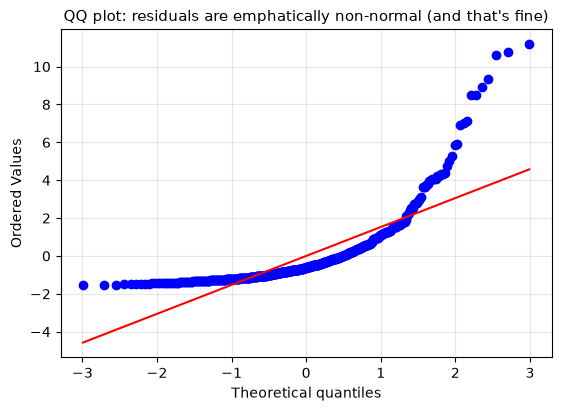

In [10]:
REPS_N = 4_000
rows = []
for n_i in [15, 50, 500]:
    x = rng.normal(0, 1, (REPS_N, n_i))
    e = rng.lognormal(0, 1, (REPS_N, n_i)) - np.exp(0.5)   # mean-zero, skewed
    y = 1.0 + 0.5 * x + e
    xc = x - x.mean(axis=1, keepdims=True)
    yc = y - y.mean(axis=1, keepdims=True)
    sxx = (xc**2).sum(axis=1)
    slope = (xc * yc).sum(axis=1) / sxx
    resid = yc - slope[:, None] * xc
    se = np.sqrt((resid**2).sum(axis=1) / (n_i - 2) / sxx)
    tc = st.t.ppf(0.975, n_i - 2)
    rows.append({"n": n_i,
                 "slope CI coverage": (np.abs(slope - 0.5) <= tc * se).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nResiduals are wildly non-normal (QQ plot below), yet the slope CI is "
      "close to\nnominal even at n=15 and indistinguishable from 0.95 by n=50. "
      "The same CLT logic\nas ./01_sampling_clt_bootstrap.ipynb, applied to "
      "coefficients.")

x1 = rng.normal(0, 1, 500)
e1 = rng.lognormal(0, 1, 500) - np.exp(0.5)
r1 = sm.OLS(1 + 0.5 * x1 + e1, sm.add_constant(x1)).fit()
fig, ax = plt.subplots(figsize=(5.5, 4))
st.probplot(r1.resid, dist="norm", plot=ax)
ax.set_title("QQ plot: residuals are emphatically non-normal (and that's fine)")
plt.show()

Where non-normality **does** bite: **prediction intervals** for individual
outcomes. A nominal 95% normal-theory PI splits its 5% miss rate 2.5%/2.5%
by construction — with skewed errors the misses pile up on one side, so your
"worst case" bound on the high side is much weaker than advertised:

In [11]:
n_tr = 2_000
x_tr = rng.normal(0, 1, n_tr)
y_tr = 1 + 0.5 * x_tr + rng.lognormal(0, 1, n_tr) - np.exp(0.5)
fit = np.polyfit(x_tr, y_tr, 1)
s_hat = np.std(y_tr - np.polyval(fit, x_tr), ddof=2)

x_te = rng.normal(0, 1, 100_000)
y_te = 1 + 0.5 * x_te + rng.lognormal(0, 1, 100_000) - np.exp(0.5)
pred = np.polyval(fit, x_te)
miss_lo = (y_te < pred - 1.96 * s_hat).mean()
miss_hi = (y_te > pred + 1.96 * s_hat).mean()
print(f"nominal 95% prediction interval, missing rate: below = {miss_lo:.3%}, "
      f"above = {miss_hi:.3%}")
print("(nominal: 2.5% each side). Total coverage looks okay, but the risk is "
      "entirely\none-sided - the upper bound is the one that lies. For honest "
      "intervals on\nindividual outcomes use quantile regression or empirical "
      "residual quantiles.")

nominal 95% prediction interval, missing rate: below = 0.000%, above = 4.637%
(nominal: 2.5% each side). Total coverage looks okay, but the risk is entirely
one-sided - the upper bound is the one that lies. For honest intervals on
individual outcomes use quantile regression or empirical residual quantiles.


### 4.3 Functional form: the diagnostic that actually earns its keep

Misspecified functional form biases both predictions and the "effect" you
report. The residual-vs-fitted plot is the workhorse check. Ad spend with
diminishing (then saturating) returns, fit linearly:

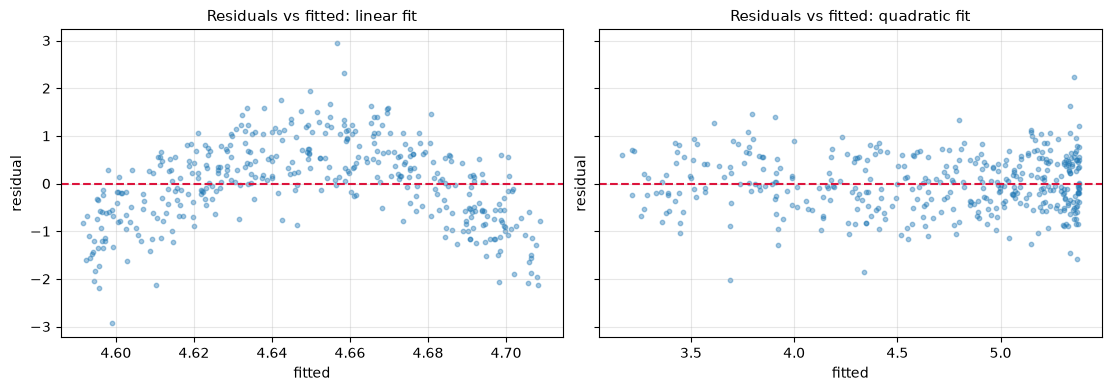

linear model:    slope = +0.01 per $k (reads 'ads always help'), RESET p = 1.8e-69
quadratic model: effect at x=2 is +0.56, at x=6 is -0.54 per $k  (true: +0.60 and -0.60)

The linear 'average slope' hides that marginal ad dollars *hurt* past the peak.
The smile in the left panel is the tell; the fix is a flexible-enough form
(polynomial, spline, or log), not a fancier test.


In [12]:
x_f = rng.uniform(0, 8, 400)                       # ad spend, $k
y_f = 3 + 1.2 * x_f - 0.15 * x_f**2 + rng.normal(0, 0.6, 400)
dff = pd.DataFrame({"x": x_f, "y": y_f})

res_lin = smf.ols("y ~ x", data=dff).fit()
res_quad = smf.ols("y ~ x + I(x**2)", data=dff).fit()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, res, name in [(axes[0], res_lin, "linear fit"),
                      (axes[1], res_quad, "quadratic fit")]:
    ax.scatter(res.fittedvalues, res.resid, s=10, alpha=0.4)
    ax.axhline(0, color="crimson", ls="--")
    ax.set(title=f"Residuals vs fitted: {name}", xlabel="fitted", ylabel="residual")
plt.show()

reset_p = linear_reset(res_lin, power=2, use_f=True).pvalue
print(f"linear model:    slope = {res_lin.params['x']:+.2f} per $k "
      f"(reads 'ads always help'), RESET p = {reset_p:.1e}")
print(f"quadratic model: effect at x=2 is "
      f"{res_quad.params['x'] + 2 * res_quad.params['I(x ** 2)'] * 2:+.2f}, "
      f"at x=6 is {res_quad.params['x'] + 2 * res_quad.params['I(x ** 2)'] * 6:+.2f} "
      "per $k  (true: +0.60 and -0.60)")
print("\nThe linear 'average slope' hides that marginal ad dollars *hurt* past "
      "the peak.\nThe smile in the left panel is the tell; the fix is a "
      "flexible-enough form\n(polynomial, spline, or log), not a fancier test.")

## 5. Multicollinearity: what it inflates and what it leaves alone

Folklore says multicollinearity "breaks regression". Precisely: when $x_1$
and $x_2$ are correlated $\rho$, the data contain little independent
variation to tell their effects apart, so the sampling variance of each
coefficient inflates by $\text{VIF} = 1/(1-\rho^2)$ (with SE scaling as
$\sqrt{\text{VIF}}$). It does **not** bias anything, does **not** hurt other
coefficients, and does **not** hurt prediction. We verify all four claims at
once: truth $y = 1 + 2x_1 + 2x_2 + 0.5x_3 + \varepsilon$, $x_3$ independent,
500 simulated datasets per $\rho$.

In [13]:
def make_X(rho, m):
    z = rng.normal(0, 1, (m, 3))
    x1 = z[:, 0]
    x2 = rho * z[:, 0] + np.sqrt(1 - rho**2) * z[:, 1]
    return np.column_stack([np.ones(m), x1, x2, z[:, 2]])

BETA_MC, SIG_MC, N_MC, REPS_MC = np.array([1.0, 2.0, 2.0, 0.5]), 2.0, 300, 500
rows, b12_store = [], {}
for rho in [0.0, 0.9, 0.99]:
    Xt = make_X(rho, 2_000)
    yt = Xt @ BETA_MC + rng.normal(0, SIG_MC, 2_000)
    b1s, b3s, sums, rmses = (np.empty(REPS_MC) for _ in range(4))
    b2s = np.empty(REPS_MC)
    for r in range(REPS_MC):
        X = make_X(rho, N_MC)
        y = X @ BETA_MC + rng.normal(0, SIG_MC, N_MC)
        bh = np.linalg.lstsq(X, y, rcond=None)[0]
        b1s[r], b2s[r], b3s[r] = bh[1], bh[2], bh[3]
        sums[r] = bh[1] + bh[2]
        rmses[r] = np.sqrt(np.mean((yt - Xt @ bh) ** 2))
    b12_store[rho] = (b1s, b2s)
    rows.append({"rho": rho, "emp SE(b1)": b1s.std(ddof=1),
                 "theory sqrt(VIF)": 1 / np.sqrt(1 - rho**2),
                 "emp SE(b3)": b3s.std(ddof=1),
                 "SD(b1+b2)": sums.std(ddof=1),
                 "test RMSE": rmses.mean()})
tab_mc = pd.DataFrame(rows).round(3)
print(tab_mc.to_string(index=False))
base_se = tab_mc["emp SE(b1)"].iloc[0]
print(f"\nSE(b1) inflation vs rho=0: "
      f"{(tab_mc['emp SE(b1)'] / base_se).round(2).tolist()}  "
      f"(theory sqrt(VIF): {tab_mc['theory sqrt(VIF)'].round(2).tolist()})")

 rho  emp SE(b1)  theory sqrt(VIF)  emp SE(b3)  SD(b1+b2)  test RMSE
0.00       0.109             1.000       0.114      0.153      1.987
0.90       0.271             2.294       0.116      0.118      2.007
0.99       0.857             7.089       0.114      0.122      2.042

SE(b1) inflation vs rho=0: [1.0, 2.49, 7.86]  (theory sqrt(VIF): [1.0, 2.29, 7.09])


Read the table columns against the claims:

- **SE(b1) explodes** with $\rho$, closely tracking $\sqrt{\text{VIF}}$:
  at $\rho = 0.99$ theory says $\sqrt{1/(1-0.99^2)} \approx 7.1\times$; the
  simulation shows ≈7.9× (500 replications of finite-sample noise).
- **SE(b3) is untouched** — collinearity is a *local* disease of the
  correlated block.
- **The sum $b_1 + b_2$ stays precisely estimated**: the data can't split
  credit between the twins but knows their combined effect. If the business
  question is "what if both move together" you never had a problem.
- **Test RMSE is flat** — prediction lives on the fitted surface, which is
  pinned down fine.

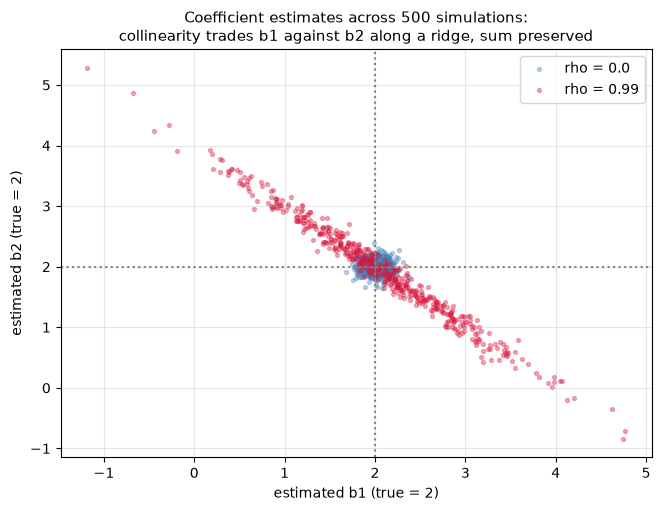

VIFs at rho = 0.99 (one dataset): {'x1': np.float64(52.6), 'x2': np.float64(52.6), 'x3': np.float64(1.0)}
Rule of thumb 'VIF > 10 is trouble' really means: SEs on those coefficients are
>3x what independent regressors would give. Whether that is 'trouble' depends
entirely on whether you needed those individual coefficients.


In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for rho, color in [(0.0, "steelblue"), (0.99, "crimson")]:
    b1s, b2s = b12_store[rho]
    ax.scatter(b1s, b2s, s=8, alpha=0.35, color=color, label=f"rho = {rho}")
ax.axhline(2, color="gray", ls=":"); ax.axvline(2, color="gray", ls=":")
ax.set(title="Coefficient estimates across 500 simulations:\ncollinearity trades "
       "b1 against b2 along a ridge, sum preserved",
       xlabel="estimated b1 (true = 2)", ylabel="estimated b2 (true = 2)")
ax.legend()
plt.show()

X_vif = make_X(0.99, N_MC)
vifs = [variance_inflation_factor(X_vif, i) for i in range(1, 4)]
print("VIFs at rho = 0.99 (one dataset):",
      dict(zip(["x1", "x2", "x3"], np.round(vifs, 1))))
print("Rule of thumb 'VIF > 10 is trouble' really means: SEs on those "
      "coefficients are\n>3x what independent regressors would give. Whether "
      "that is 'trouble' depends\nentirely on whether you needed those "
      "individual coefficients.")

**What to do about it** (when you do need the individual coefficients): get
more data (SEs shrink with $\sqrt{n}$ regardless), find variation that
separates the twins (experiments, natural experiments), combine them into an
index if only the aggregate is meaningful, or regularize — accepting that the
estimand changes (§6). **Never** drop a confounder just because it is
collinear with your treatment: that trades honest variance for silent bias
(§3).

## 6. Regularization: ridge, lasso, and what "selected" does not mean

Ridge adds $\lambda\sum\beta_j^2$, lasso $\lambda\sum|\beta_j|$ to the loss.
Both shrink coefficients toward zero to cut variance; lasso's corner at zero
sets coefficients *exactly* to zero — selection for free. The classic
coefficient-path picture, on data with 6 true signals among 20 correlated
features:

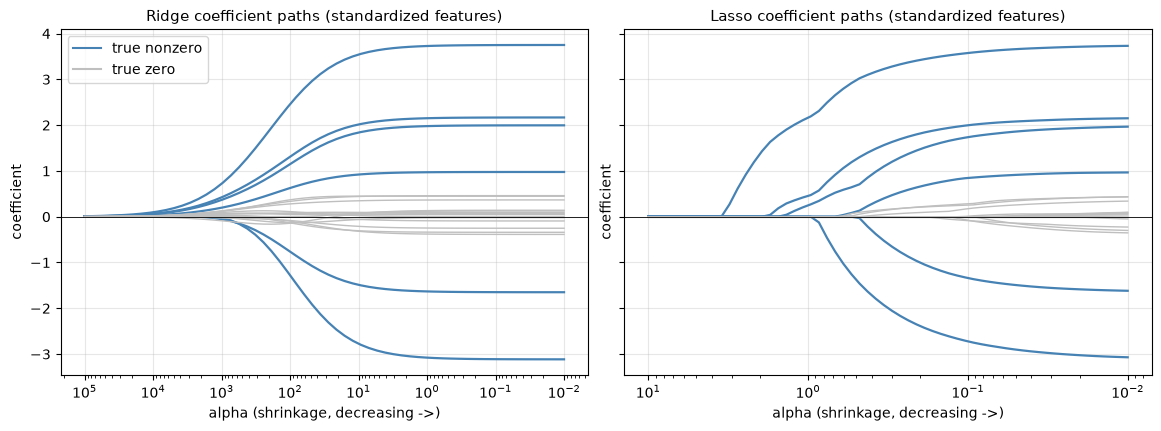

Ridge shrinks everything smoothly, never to exactly zero; lasso zeroes the gray
(true-zero) features over most of its path (all 14 exactly zero for 80% of alphas > 0.3) while keeping the blue signals.


In [15]:
p_reg, n_reg = 20, 300
L_chol = np.linalg.cholesky(toeplitz(0.6 ** np.arange(p_reg)))
X_reg = rng.normal(0, 1, (n_reg, p_reg)) @ L_chol.T
beta_reg = np.zeros(p_reg)
beta_reg[:6] = [4, -3, 2.5, 2, -1.5, 1]
y_reg = X_reg @ beta_reg + rng.normal(0, 3, n_reg)

Xs = StandardScaler().fit_transform(X_reg)
yc = y_reg - y_reg.mean()

alphas_l = np.logspace(1.0, -2, 60)
_, coefs_lasso, _ = lasso_path(Xs, yc, alphas=alphas_l, max_iter=10_000)
alphas_r = np.logspace(5, -2, 60)
coefs_ridge = np.array([Ridge(alpha=a, fit_intercept=False).fit(Xs, yc).coef_
                        for a in alphas_r]).T

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, (alphas, coefs, name) in zip(
        axes, [(alphas_r, coefs_ridge, "Ridge"), (alphas_l, coefs_lasso, "Lasso")]):
    for j in range(p_reg):
        ax.plot(alphas, coefs[j], color="steelblue" if beta_reg[j] != 0 else "0.75",
                lw=1.6 if beta_reg[j] != 0 else 1.0)
    ax.set_xscale("log")
    ax.invert_xaxis()
    ax.set(title=f"{name} coefficient paths (standardized features)",
           xlabel="alpha (shrinkage, decreasing ->)", ylabel="coefficient")
    ax.axhline(0, color="black", lw=0.6)
axes[0].legend(handles=[Line2D([], [], color="steelblue", label="true nonzero"),
                        Line2D([], [], color="0.75", label="true zero")])
plt.show()

n_zero_kept = (np.abs(coefs_lasso[6:, alphas_l > 0.3]) < 1e-10).all(axis=0).mean()
print("Ridge shrinks everything smoothly, never to exactly zero; lasso zeroes "
      "the gray\n(true-zero) features over most of its path "
      f"(all 14 exactly zero for {100 * n_zero_kept:.0f}% of alphas > 0.3) while "
      "keeping the blue signals.")

### 6.1 Why you must standardize

The penalty is on raw coefficient *magnitudes*, so units are destiny: a
feature measured in cents has a 100× smaller coefficient than the same
feature in dollars and gets 100× less penalty pressure. Two features below
carry **identical per-standard-deviation effects**; only their units differ.
Unstandardized lasso keeps one and kills the other — an artifact of
measurement units, not of information:

In [16]:
n_std = 400
z1, z2 = rng.normal(0, 1, (2, n_std))
x_cents = 100 * z1                      # e.g. spend recorded in cents
x_score = z2                            # e.g. a unit-variance score
y_std = 0.02 * x_cents + 2.0 * x_score + rng.normal(0, 1, n_std)
X_raw = np.column_stack([x_cents, x_score])

raw_coefs = Lasso(alpha=20.0).fit(X_raw, y_std).coef_
std_coefs = Lasso(alpha=0.5).fit(StandardScaler().fit_transform(X_raw),
                                 y_std - y_std.mean()).coef_

print(pd.DataFrame({"true effect per SD": [2.0, 2.0],
                    "lasso on raw units": raw_coefs.round(3),
                    "lasso standardized": std_coefs.round(3)},
                   index=["x_cents", "x_score"]))
print("\nRaw units: the cents feature survives (its coefficient is numerically "
      "tiny, so\nthe penalty barely feels it) while the equally informative "
      "score is zeroed.\nStandardized: both are kept, symmetrically - as they "
      "should be. sklearn does NOT\nstandardize for you; do it explicitly (or "
      "in a Pipeline).")

         true effect per SD  lasso on raw units  lasso standardized
x_cents                 2.0               0.018               1.432
x_score                 2.0               0.000               1.497

Raw units: the cents feature survives (its coefficient is numerically tiny, so
the penalty barely feels it) while the equally informative score is zeroed.
Standardized: both are kept, symmetrically - as they should be. sklearn does NOT
standardize for you; do it explicitly (or in a Pipeline).


### 6.2 The post-selection caveat: lasso picks predictors, not causes

Lasso's selection is a *predictive economy*: among correlated features it
keeps whichever cheapest-to-keep combination predicts well — which one gets
kept is close to arbitrary, and the surviving coefficients are shrunk
(biased) with no valid naive SEs. Setup: $x_1$ truly drives $y$; $x_2$ is
just correlated with $x_1$ ($\rho = 0.95$, true effect **zero**); six pure
noise features. We refit lasso on 300 bootstrap resamples and count what gets
"selected":

In [17]:
n_ps = 150
x1_ps = rng.normal(0, 1, n_ps)
x2_ps = 0.95 * x1_ps + np.sqrt(1 - 0.95**2) * rng.normal(0, 1, n_ps)
X_ps = np.column_stack([x1_ps, x2_ps, rng.normal(0, 1, (n_ps, 6))])
y_ps = 0.6 * x1_ps + rng.normal(0, 1, n_ps)

Xs_ps = StandardScaler().fit_transform(X_ps)
alpha_cv = LassoCV(cv=5, max_iter=20_000).fit(Xs_ps, y_ps).alpha_

B_ps = 300
sel = np.zeros((B_ps, 8), dtype=bool)
for b_i in range(B_ps):
    idx = rng.integers(0, n_ps, n_ps)
    sel[b_i] = Lasso(alpha=alpha_cv, max_iter=20_000).fit(
        Xs_ps[idx], y_ps[idx]).coef_ != 0

freq = sel.mean(axis=0)
print(f"CV-chosen alpha: {alpha_cv:.3f}   (selection frequency over {B_ps} "
      "bootstrap refits)")
print(f"  x1 (true driver, beta=0.6): selected {freq[0]:.0%}")
print(f"  x2 (true beta = 0, corr 0.95 with x1): selected {freq[1]:.0%}")
print(f"  x1 dropped while x2 kept: "
      f"{(~sel[:, 0] & sel[:, 1]).mean():.0%} of refits")
print(f"  avg number of the 6 noise features selected: {sel[:, 2:].sum(1).mean():.2f}")

ols_b1 = sm.OLS(y_ps, sm.add_constant(Xs_ps[:, 0])).fit().params[1]
lasso_b1 = Lasso(alpha=alpha_cv, max_iter=20_000).fit(Xs_ps, y_ps).coef_[0]
print(f"\nfull-data coefficient on x1: lasso {lasso_b1:+.3f} vs "
      f"bivariate OLS {ols_b1:+.3f}  (shrinkage bias toward zero)")

CV-chosen alpha: 0.073   (selection frequency over 300 bootstrap refits)
  x1 (true driver, beta=0.6): selected 98%
  x2 (true beta = 0, corr 0.95 with x1): selected 73%
  x1 dropped while x2 kept: 2% of refits
  avg number of the 6 noise features selected: 3.30

full-data coefficient on x1: lasso +0.464 vs bivariate OLS +0.678  (shrinkage bias toward zero)


Three lessons a senior candidate should volunteer:

1. **Selection is unstable**: the truly-null-but-correlated $x_2$ gets
   "selected" in roughly three quarters of resamples, and occasionally
   *replaces* the true driver entirely. "Lasso kept it" ≠ "it matters".
2. **Coefficients are biased by design** (shrinkage) — never quote a lasso
   coefficient as an effect size.
3. **Naive SEs/p-values after selection are invalid** — the selection event
   itself used the data. Honest options: sample-split, or design-based
   methods like post-double-selection / debiased lasso when you need
   inference on a focal coefficient
   (see `../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb` for
   the ML-assisted-causal mindset).

**Ridge vs lasso, when each**: many small correlated effects and you care
about prediction → ridge (it shares credit smoothly; lasso's arbitrary picks
cost accuracy). Truly sparse world or you need a short feature list → lasso.
Unsure → elastic net, and let CV decide. For pure tabular prediction, all of
these usually lose to boosting
(`../04_ml_tabular/01_gradient_boosting_mastery.ipynb`) — the reason to stay
linear is interpretability and stability, so protect those properly.

## 7. Logistic regression: odds ratios vs average marginal effects

Logistic coefficients are log-odds-ratios — exact, convenient, and
systematically misread as probability changes. Stakeholders want
**percentage points**; for that, compute **average marginal effects** (AME).
Simulated conversion data: a discount flag, past purchase count, mobile flag,
with known coefficients:

In [18]:
n_c = 8_000
conv = pd.DataFrame({
    "discount": rng.binomial(1, 0.30, n_c),
    "past_purchases": rng.poisson(2.0, n_c),
    "is_mobile": rng.binomial(1, 0.55, n_c),
})
eta = -2.2 + 0.5 * conv["discount"] + 0.35 * conv["past_purchases"] \
      - 0.4 * conv["is_mobile"]
conv["converted"] = rng.binomial(1, 1 / (1 + np.exp(-eta)))

res_log = smf.logit("converted ~ discount + past_purchases + is_mobile",
                    data=conv).fit(disp=0)

or_tab = pd.DataFrame({"coef (log-odds)": res_log.params,
                       "odds ratio": np.exp(res_log.params),
                       "true OR": np.exp(pd.Series(
                           {"Intercept": -2.2, "discount": 0.5,
                            "past_purchases": 0.35, "is_mobile": -0.4}))}).round(3)
print(or_tab)
print(f"\noverall conversion rate: {conv['converted'].mean():.3f}")

                coef (log-odds)  odds ratio  true OR
Intercept                -2.146       0.117    0.111
discount                  0.403       1.496    1.649
past_purchases            0.359       1.432    1.419
is_mobile                -0.498       0.608    0.670

overall conversion rate: 0.186


In [19]:
ame = res_log.get_margeff(at="overall", dummy=True)
print(ame.summary_frame().round(4))

# manual AME for the discount dummy: average counterfactual contrast
p1 = res_log.predict(conv.assign(discount=1))
p0 = res_log.predict(conv.assign(discount=0))
print(f"\nmanual AME for discount: mean[p(d=1) - p(d=0)] = {(p1 - p0).mean():+.4f}")
print(f"odds-ratio reading: discount multiplies the *odds* by "
      f"{np.exp(res_log.params['discount']):.2f} (+"
      f"{100 * (np.exp(res_log.params['discount']) - 1):.0f}% odds)")
print(f"AME reading:        discount adds ~{100 * (p1 - p0).mean():.1f} "
      "percentage points of conversion probability, averaged over customers")
print("\nBoth are correct; only the second answers 'how many extra conversions "
      "do we get?'.\nNever present an odds ratio as 'X% more likely to convert'.")

                 dy/dx  Std. Err.        z  Pr(>|z|)  Conf. Int. Low  Cont. Int. Hi.
discount        0.0601     0.0096   6.2480       0.0          0.0413          0.0790
past_purchases  0.0512     0.0027  18.8065       0.0          0.0459          0.0566
is_mobile      -0.0719     0.0086  -8.3641       0.0         -0.0888         -0.0551



manual AME for discount: mean[p(d=1) - p(d=0)] = +0.0601
odds-ratio reading: discount multiplies the *odds* by 1.50 (+50% odds)
AME reading:        discount adds ~6.0 percentage points of conversion probability, averaged over customers

Both are correct; only the second answers 'how many extra conversions do we get?'.
Never present an odds ratio as 'X% more likely to convert'.


The same log-odds coefficient implies a *different* probability change at
every baseline rate — largest near 50%, tiny in the tails. That is why a
single odds ratio cannot be translated to percentage points without saying
*for whom*:

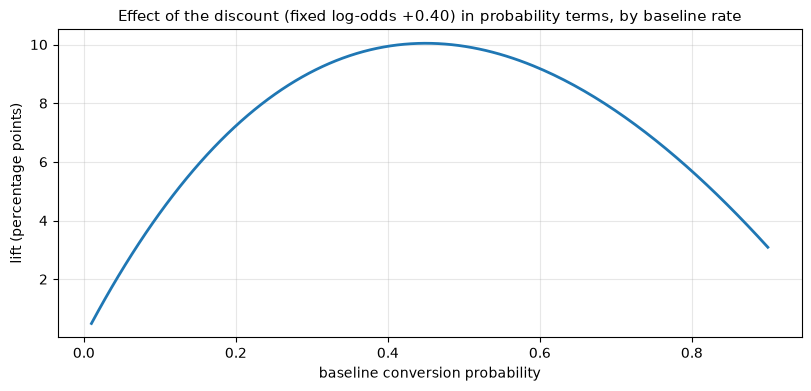

mean predicted = 0.186125, observed rate = 0.186125  (equal by the score equations)
                  mean_pred  mean_obs     n
p_hat                                      
(0.0654, 0.0924]      0.084     0.086  1221
(0.0924, 0.105]       0.102     0.098   528
(0.105, 0.127]        0.127     0.131   850
(0.127, 0.143]        0.139     0.145  1042
(0.143, 0.173]        0.167     0.163   713
(0.173, 0.193]        0.189     0.186  1066
(0.193, 0.2]          0.200     0.150   294
(0.2, 0.256]          0.244     0.236   935
(0.256, 0.33]         0.297     0.325   733
(0.33, 0.748]         0.412     0.409   618

Calibration is tight across bins (thin-bin wiggles are binomial noise): a correctly
specified logistic regression is naturally calibrated - a property boosted trees
and SVMs lack out of the box. More in ../04_ml_tabular/03_evaluation_calibration.ipynb.


In [20]:
p_base = np.linspace(0.01, 0.9, 200)
b_d = res_log.params["discount"]
p_after = 1 / (1 + np.exp(-(np.log(p_base / (1 - p_base)) + b_d)))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(p_base, 100 * (p_after - p_base), lw=2)
ax.set(title=f"Effect of the discount (fixed log-odds {b_d:+.2f}) in probability "
       "terms, by baseline rate",
       xlabel="baseline conversion probability", ylabel="lift (percentage points)")
plt.show()

# calibration: logistic MLE with an intercept is calibrated on average in-sample
conv["p_hat"] = res_log.predict(conv)
print(f"mean predicted = {conv['p_hat'].mean():.6f}, "
      f"observed rate = {conv['converted'].mean():.6f}  (equal by the score "
      "equations)")
cal = (conv.groupby(pd.qcut(conv["p_hat"], 10, duplicates="drop"), observed=True)
       .agg(mean_pred=("p_hat", "mean"), mean_obs=("converted", "mean"),
            n=("p_hat", "size")))
print(cal.round(3).to_string())
print("\nCalibration is tight across bins (thin-bin wiggles are binomial noise): "
      "a correctly\nspecified logistic regression is naturally calibrated - a "
      "property boosted trees\nand SVMs lack out of the box. More in "
      "../04_ml_tabular/03_evaluation_calibration.ipynb.")

## 8. Pitfalls

### Pitfall 1: predicting levels from a log-model with a naive `exp()`

$E[\log y] \ne \log E[y]$. Exponentiating fitted values from a log-y model
estimates the conditional **median**, not the mean — with lognormal-ish
errors the naive forecast is low by a factor of $e^{\sigma^2/2}$. On
revenue-style noise ($\sigma = 0.7$) that factor is ≈1.28: the naive total
runs **~22–23% short of actuals**. Duan's smearing factor (mean of
exponentiated residuals) fixes it without assuming normality:

In [21]:
n_r = 3_000
lx = rng.normal(0, 1, n_r)
ly = 1.0 + 0.5 * lx + rng.normal(0, 0.7, n_r)
y_lvl = np.exp(ly)

res_r = sm.OLS(ly, sm.add_constant(lx)).fit()
naive = np.exp(res_r.fittedvalues)
smear = np.exp(res_r.resid).mean()

print(f"actual total:            {y_lvl.sum():12,.0f}")
print(f"naive exp() forecast:    {naive.sum():12,.0f}   "
      f"({100 * (naive.sum() / y_lvl.sum() - 1):+.1f}%)")
print(f"smearing-corrected:      {(naive * smear).sum():12,.0f}   "
      f"({100 * (naive * smear).sum() / y_lvl.sum() - 100:+.1f}%)")
print(f"\nsmearing factor = mean(exp(resid)) = {smear:.3f}; "
      f"lognormal theory exp(sigma^2/2) = {np.exp(0.49 / 2):.3f}")
print("Forecast revenue with a naive exp() and you will 'mysteriously' miss "
      "plan every\nquarter. Same trap when back-transforming log-forecasts in "
      "time series.")

actual total:                  12,041
naive exp() forecast:           9,259   (-23.1%)
smearing-corrected:            11,991   (-0.4%)

smearing factor = mean(exp(resid)) = 1.295; lognormal theory exp(sigma^2/2) = 1.278
Forecast revenue with a naive exp() and you will 'mysteriously' miss plan every
quarter. Same trap when back-transforming log-forecasts in time series.


### Pitfall 2: R² worship

R² measures variance explained — it says nothing about whether a coefficient
is trustworthy (§3's confounded regression fit respectably with the wrong
*sign*) and nothing about whether an effect is valuable. An email campaign
with a microscopic R² can still be precisely measured and worth real money:

In [22]:
n_r2 = 200_000
treat = rng.binomial(1, 0.5, n_r2)
spend = 50 + 0.6 * treat + rng.normal(0, 20, n_r2)   # true lift: $0.60/user
res_r2 = sm.OLS(spend, sm.add_constant(treat)).fit()
ci = res_r2.conf_int()[1]

print(f"R-squared: {res_r2.rsquared:.5f}   <- 'useless model'?")
print(f"lift estimate: ${res_r2.params[1]:.2f} per user, "
      f"95% CI [${ci[0]:.2f}, ${ci[1]:.2f}], t = {res_r2.tvalues[1]:.1f}")
print(f"at 10M users/quarter: ${res_r2.params[1] * 10e6 / 1e6:.1f}M "
      "incremental revenue")
print("\nIndividual spend is mostly idiosyncratic (huge residual variance), so "
      "R^2 is\ntiny even though the lift is precisely bounded away from zero. "
      "Judge inference\nby SEs and design; judge prediction by held-out error; "
      "judge neither by R^2 alone.")

R-squared: 0.00034   <- 'useless model'?
lift estimate: $0.74 per user, 95% CI [$0.56, $0.91], t = 8.2
at 10M users/quarter: $7.4M incremental revenue

Individual spend is mostly idiosyncratic (huge residual variance), so R^2 is
tiny even though the lift is precisely bounded away from zero. Judge inference
by SEs and design; judge prediction by held-out error; judge neither by R^2 alone.


### Pitfall 3: extrapolating a fitted curve outside the data

Flexible forms fit the observed range and are pure fiction outside it. A
degree-5 polynomial fits the §4.3 ad-spend data in [0, 8] $k essentially as
well as the quadratic — inside the data they are indistinguishable — then
gets asked about $12k:

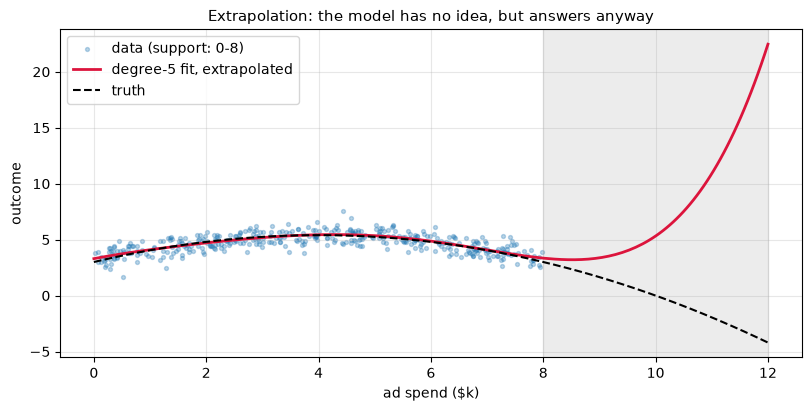

degree-5 prediction at x=12: 22.5   truth: -4.2
Always report the support of your data next to any 'what if we doubled X' answer.


In [23]:
res_poly = np.polyfit(x_f, y_f, 5)
x_ext = np.linspace(0, 12, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x_f, y_f, s=8, alpha=0.3, label="data (support: 0-8)")
ax.plot(x_ext, np.polyval(res_poly, x_ext), color="crimson", lw=2,
        label="degree-5 fit, extrapolated")
ax.plot(x_ext, 3 + 1.2 * x_ext - 0.15 * x_ext**2, color="black", ls="--",
        label="truth")
ax.axvspan(8, 12, color="gray", alpha=0.15)
ax.set(title="Extrapolation: the model has no idea, but answers anyway",
       xlabel="ad spend ($k)", ylabel="outcome")
ax.legend()
plt.show()
print(f"degree-5 prediction at x=12: {np.polyval(res_poly, 12):.1f}   "
      f"truth: {3 + 1.2 * 12 - 0.15 * 144:.1f}")
print("Always report the support of your data next to any 'what if we doubled "
      "X' answer.")

### Pitfall 4 (no code, big consequences): "control for everything"

Adding controls is not monotonically safer. Conditioning on **colliders** or
**post-treatment variables** (e.g. controlling for site visits when
estimating an email's effect on purchases) *introduces* bias that wasn't
there. Which controls are good vs bad is a causal-graph question, worked
through in `../03_causal_inference/01_potential_outcomes_dags.ipynb`.

## 9. Interview corner

**Q1. "In `log(units) ~ log(price) + controls`, the price coefficient is
−1.8. Interpret it."**
A 1% price increase is associated with ≈1.8% fewer units — an elasticity —
holding the controls fixed; exact form $(1.01^{-1.8}-1)$. Volunteer the
caveats: it's an average over the observed price range; it is *causal only
if* price variation is exogenous conditional on controls (usually false —
managers price into demand, §3); with an interaction present, state at what
covariate values it applies.

**Q2. "What breaks OLS standard errors?"**
Heteroskedasticity (naive SEs undercover — fix: HC/robust); dependence:
clustered or serially correlated errors (the big one in product data — fix:
cluster-robust/block bootstrap, see `../02_ab_testing/05...`); leverage
points at small n (HC3 over HC1); misspecification (then the SE is for the
wrong estimand anyway). Explicitly *not* on the list at realistic n:
residual non-normality. Measurement error in x biases the coefficient
itself — no SE can rescue that.

**Q3. "Ridge vs lasso — when would you use each?"**
Ridge: correlated features, many small effects, prediction focus — shares
credit, never zeroes, stable. Lasso: believed-sparse truth or a hard
requirement for a short feature list — but selection is unstable under
correlation and coefficients are shrunk. Elastic net hedges. Standardize
first, tune by CV. Neither yields valid naive inference; if a coefficient
must be defended, use OLS on a pre-registered spec or debiased/post-double-
selection methods.

**Q4. "Can I claim causality from this regression?"**
Only with an identification argument, never from the fit itself: why is the
regressor as-good-as-random conditional on controls? Randomization, an
instrument, a discontinuity, a diff-in-diff design — otherwise you have a
conditional association. Mention OVB direction reasoning (can you sign the
bias?) and that R², significance, and sample size are all silent on this.
Deep dive: `../03_causal_inference/`.

**Q5. "Your two ad channels are correlated 0.95 and their coefficients have
huge SEs. Is the regression broken?"**
No — it is honestly reporting that the data cannot separate the channels.
Their *sum* is well estimated, prediction is unaffected, other coefficients
are fine (§5). Options: report the combined effect, get separating variation
(geo experiments), or regularize with the estimand change acknowledged.
Dropping one channel silently reassigns its credit to the other.

**Q6. "The promo coefficient tripled when you removed the interaction term.
Which is right?"**
Both, for different questions: with `promo × price`, the promo main effect is
the lift at price = 0 (or at the centering point); without it, it's an
average lift. Check centering, then report effects at named price points or
an average marginal effect. This is a specification-reading question, not a
bug hunt.

**Q7. "Your logistic model says the discount's odds ratio is 1.65. Marketing
asks: 'so 65% more conversions?'"**
No — odds, not probability. Compute the AME (≈ +6 percentage points in §7)
and note the lift in pp varies with baseline rate (largest near 50%). Offer
both: OR for the model card, AME (or counterfactual rates) for the business
decision.

## 10. Key takeaways

- Decide the job first — inference or prediction — because variable choice,
  regularization, and diagnostics all differ between them.
- Coefficient reading is mechanical once you know the form: levels = units,
  log-y = ~percent per unit ($e^b-1$ exact), log-x = units per percent,
  log-log = elasticity; dummies in log models are multiplicative.
- With interactions, main effects are effects *at zero of the partner
  variable* — center on a meaningful reference point or report effects at
  named values.
- OVB is exact arithmetic: bias = (omitted → y effect) × (omitted ↔ included
  slope). Sign it before you run anything; a confounded regression can fit
  beautifully and flip the sign of the truth.
- Worry hierarchy for diagnostics: identification ≫ functional form ≫ SE
  validity (robust/clustered) ≫ residual normality (mostly irrelevant for
  coefficients at scale; matters for prediction intervals).
- Heteroskedasticity leaves coefficients unbiased but makes naive CIs
  undercover — robust (HC) SEs are the observational-data default.
- Multicollinearity inflates SEs of the collinear coefficients by
  $\sqrt{\text{VIF}}$ and nothing else — prediction, other coefficients, and
  the collinear *sum* are fine.
- Standardize before regularizing; lasso "selection" is a predictive
  convenience — unstable under correlation, coefficients shrunk, naive
  post-selection inference invalid.
- Logistic regression: report odds ratios to modelers and AMEs (percentage
  points) to decision-makers; a correctly specified logit is naturally
  calibrated.
- Apply $e^{\hat\sigma^2/2}$ (or Duan smearing) when transforming log-model
  predictions back to levels — otherwise your revenue forecasts run low by a
  factor of $e^{\sigma^2/2}$.

## 11. Exercises

**Exercise 1 — measurement error attenuates elasticities.** Suppose the
*true* log-price sensitivity is −1.8, but you observe log-price with classical
measurement error: $\widetilde{lp} = lp + u$, $u \sim N(0, \tau^2)$ (think:
list price recorded, transaction price actual). Theory says the OLS slope
shrinks by $\lambda = \frac{\text{Var}(lp)}{\text{Var}(lp) + \tau^2}$.
Simulate with $\text{sd}(lp) = 0.4$ and $\tau \in \{0, 0.2, 0.4\}$ and verify
the attenuation factor. Why don't robust SEs help here?

In [24]:
# --- Solution ---
n_me = 20_000
lp_me = rng.normal(0, 0.4, n_me)
lu_me = 4.6 - 1.8 * lp_me + rng.normal(0, 0.3, n_me)

rows = []
for tau in [0.0, 0.2, 0.4]:
    lp_obs = lp_me + rng.normal(0, tau, n_me)
    slope = sm.OLS(lu_me, sm.add_constant(lp_obs)).fit().params[1]
    lam = 0.4**2 / (0.4**2 + tau**2)
    rows.append({"tau": tau, "lambda (theory)": lam,
                 "predicted slope": -1.8 * lam, "estimated slope": slope})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nWith noise as large as the signal (tau = 0.4 = sd(lp)), half the "
      "elasticity\nvanishes. This is *bias*, not imprecision - more data and "
      "robust SEs change\nnothing. Fixes require design: better measurement, or "
      "instrumenting the noisy\nregressor with a second independent measurement "
      "(../03_causal_inference/04_iv_rdd.ipynb).")

 tau  lambda (theory)  predicted slope  estimated slope
 0.0              1.0            -1.80           -1.797
 0.2              0.8            -1.44           -1.435
 0.4              0.5            -0.90           -0.890

With noise as large as the signal (tau = 0.4 = sd(lp)), half the elasticity
vanishes. This is *bias*, not imprecision - more data and robust SEs change
nothing. Fixes require design: better measurement, or instrumenting the noisy
regressor with a second independent measurement (../03_causal_inference/04_iv_rdd.ipynb).


**Exercise 2 — HC1 vs HC3 when n is small and x has leverage.** Robust SEs
come in flavors. With n = 40, a skewed (lognormal) regressor, and error SD
proportional to x, run 2,000 simulations and compare 95% CI coverage using
naive, HC1, and HC3 SEs. Which should be your small-sample default?

In [25]:
# --- Solution ---
REPS_E2, N_E2 = 2_000, 40
tcrit_e2 = st.t.ppf(0.975, N_E2 - 2)
cov = {"naive": 0, "HC1": 0, "HC3": 0}
for r in range(REPS_E2):
    x = np.exp(rng.normal(0, 1, N_E2))
    y = 1 + 0.5 * x + rng.normal(0, 0.5 * x)
    res = sm.OLS(y, sm.add_constant(x)).fit()
    err = abs(res.params[1] - 0.5)
    cov["naive"] += err <= tcrit_e2 * res.bse[1]
    cov["HC1"] += err <= tcrit_e2 * np.asarray(res.HC1_se)[1]
    cov["HC3"] += err <= tcrit_e2 * np.asarray(res.HC3_se)[1]
print({k: round(v / REPS_E2, 3) for k, v in cov.items()}, " (nominal 0.95)")
print("\nAll robust flavors agree asymptotically, but at small n with leverage "
      "points\nHC1 still undercovers noticeably; HC3 (which inflates residuals "
      "by 1/(1-h_i)^2,\na jackknife approximation) is the safer small-sample "
      "default - the reason\nStata's `, robust` (HC1) and R sandwich defaults "
      "differ is exactly this.")

{'naive': np.float64(0.481), 'HC1': np.float64(0.702), 'HC3': np.float64(0.878)}  (nominal 0.95)

All robust flavors agree asymptotically, but at small n with leverage points
HC1 still undercovers noticeably; HC3 (which inflates residuals by 1/(1-h_i)^2,
a jackknife approximation) is the safer small-sample default - the reason
Stata's `, robust` (HC1) and R sandwich defaults differ is exactly this.


**Exercise 3 — when does ridge beat OLS for prediction?** Fix n = 100 with
dense small coefficients (all $\beta_j = 0.2$) and grow p from 10 to 90.
Compare out-of-sample RMSE of OLS vs ridge (alpha by leave-one-out CV) over
60 replications per p. Where does OLS fall apart, and why?

 p  OLS test RMSE  ridge test RMSE
10          1.062            1.051
30          1.208            1.142
50          1.413            1.265
70          1.828            1.405
90          3.521            1.677


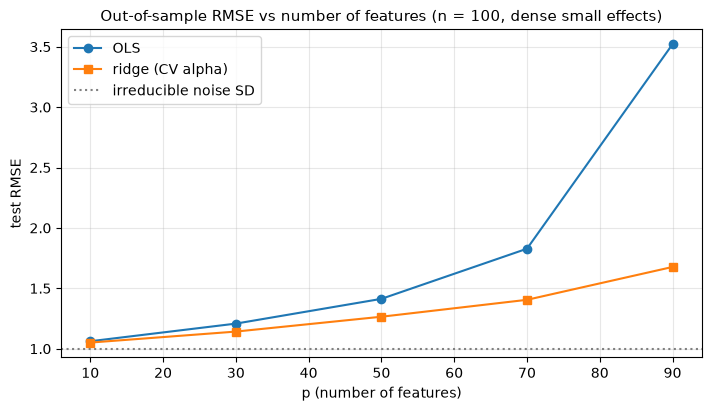

OLS variance scales like sigma^2 * p/(n-p): tolerable at p=10, ruinous as p -> n
(at p=90 only 10 residual degrees of freedom remain). Ridge trades a little bias
for a lot of variance and barely degrades - the textbook bias-variance win, and
why 'just add features, OLS is unbiased' is bad advice for prediction.


In [26]:
# --- Solution ---
N_E3, REPS_E3 = 100, 60
p_grid_e3 = [10, 30, 50, 70, 90]
alphas_cv = np.logspace(-2, 3, 15)
res_rows = []
for p in p_grid_e3:
    beta_p = np.full(p, 0.2)
    mse_ols, mse_ridge = np.empty(REPS_E3), np.empty(REPS_E3)
    for r in range(REPS_E3):
        X = rng.normal(0, 1, (N_E3, p))
        y = X @ beta_p + rng.normal(0, 1, N_E3)
        Xte = rng.normal(0, 1, (400, p))
        yte = Xte @ beta_p + rng.normal(0, 1, 400)
        b_ols = np.linalg.lstsq(np.column_stack([np.ones(N_E3), X]), y,
                                rcond=None)[0]
        mse_ols[r] = np.mean((yte - b_ols[0] - Xte @ b_ols[1:]) ** 2)
        rr = RidgeCV(alphas=alphas_cv).fit(X, y)
        mse_ridge[r] = np.mean((yte - rr.predict(Xte)) ** 2)
    res_rows.append({"p": p, "OLS test RMSE": np.sqrt(mse_ols.mean()),
                     "ridge test RMSE": np.sqrt(mse_ridge.mean())})
tab_e3 = pd.DataFrame(res_rows).round(3)
print(tab_e3.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tab_e3["p"], tab_e3["OLS test RMSE"], "o-", label="OLS")
ax.plot(tab_e3["p"], tab_e3["ridge test RMSE"], "s-", label="ridge (CV alpha)")
ax.axhline(1.0, color="gray", ls=":", label="irreducible noise SD")
ax.set(title=f"Out-of-sample RMSE vs number of features (n = {N_E3}, dense "
       "small effects)", xlabel="p (number of features)", ylabel="test RMSE")
ax.legend()
plt.show()
print("OLS variance scales like sigma^2 * p/(n-p): tolerable at p=10, ruinous "
      "as p -> n\n(at p=90 only 10 residual degrees of freedom remain). Ridge "
      "trades a little bias\nfor a lot of variance and barely degrades - the "
      "textbook bias-variance win, and\nwhy 'just add features, OLS is "
      "unbiased' is bad advice for prediction.")